In [1]:
import pickle
import warnings
from pathlib import Path

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import bootstrap as scipy_bootstrap

# ----------------------------------------------------------------------
# Roots & output
# ----------------------------------------------------------------------
HJN_ROOT  = Path("/home/thomasdev/Desktop/Hamilton_Jacobi_NN/Hamilton_Jacobi_NN")
BASE_ROOT = Path("/home/thomasdev/Desktop/noethers_projects/noethers-razor")

FIG_DIR = HJN_ROOT / "manuscript_figures"        # all paper figures land here
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ----------------------------------------------------------------------
# Statistics config (frozen to match plot_summary_statistics)
# ----------------------------------------------------------------------
CONF_LEVEL = 0.95
N_BOOT     = 10_000

# ----------------------------------------------------------------------
# Colorblind-safe palette (Okabe-Ito)
# ----------------------------------------------------------------------
PALETTE = {
    'HJN':      '#D55E00',   # vermillion  (ours)
    'Baseline': '#0072B2',   # blue        (Noether's Razor)
    'Truth':    '#000000',   # black       (ground truth; unused in Exp 1)
}
METHOD_LABEL = {'HJN': 'HJN (ours)', 'Baseline': "Noether's Razor"}
METHOD_ORDER = ['Baseline', 'HJN']   # draw baseline first so HJN sits on top

# ----------------------------------------------------------------------
# Figure style — adjust ONE block per venue, everything inherits
# ----------------------------------------------------------------------
FIG_CONFIG = {
    'text_width_in': 6.9,    # full text width: NeurIPS/ICML 2-col ~6.9", single-col ~3.3"
    'panel_aspect':  0.80,   # panel height / width
    'font_size':     9,
    'tick_size':     8,
    'legend_size':   8,
    'use_tex':       False,  # True ONLY if a LaTeX install is present (exact font match)
    'font_family':   'serif',
}

def apply_style(cfg=FIG_CONFIG):
    mpl.rcParams.update({
        'pdf.fonttype': 42, 'ps.fonttype': 42,        # embed real fonts (publisher-safe)
        'savefig.dpi': 300, 'figure.dpi': 120,
        'savefig.bbox': 'tight',
        'font.size': cfg['font_size'],
        'axes.titlesize': cfg['font_size'],
        'axes.labelsize': cfg['font_size'],
        'xtick.labelsize': cfg['tick_size'],
        'ytick.labelsize': cfg['tick_size'],
        'legend.fontsize': cfg['legend_size'],
        'axes.grid': True, 'grid.alpha': 0.3,
        'axes.linewidth': 0.8,
        'lines.linewidth': 1.2,
        'font.family': cfg['font_family'],
        'text.usetex': cfg['use_tex'],
        'mathtext.fontset': 'cm',
    })

apply_style()


# ----------------------------------------------------------------------
# Task metadata shared by all three experiments
# ----------------------------------------------------------------------
TASK_LABEL = {
    1: 'Task 1\nIdeal mass–spring',
    2: 'Task 2\nIdeal pendulum',
    3: 'Task 3\nReal pendulum',
    4: 'Task 4\nHénon–Heiles',
}

# Which canonical pair (q_i, p_i) the Exp-2 phase panel shows, per task.
# n=1 tasks have one pair. Task 4 uses (y, p_y): the DOF carrying the
# asymmetric cubic term -y^3/3, where anharmonicity is most visible.
PHASE_PAIR   = {1: 0, 2: 0, 3: 0, 4: 1}
PHASE_LABELS = {1: ('$q$', '$p$'), 2: ('$q$', '$p$'),
                3: ('$q$', '$p$'), 4: ('$y$', '$p_y$')}

def _dof(a, i=0):
    """(T,) -> (T,) unchanged; (T,n) -> column i. Lets n=1 pickles flow through."""
    a = np.asarray(a)
    return a if a.ndim == 1 else a[:, i]

def _dof2d(a):
    """(T,) -> (T,1); (T,n) -> unchanged."""
    a = np.asarray(a)
    return a[:, None] if a.ndim == 1 else a

In [2]:
DATASETS = ['multiple_periods', 'high_energy']   # main body / appendix
TASKS    = [1, 2, 4]
ACC_SUB  = "prediction_results_all_trajectories"
TIM_SUB  = "benchmark_outputs"

# Accuracy filenames are identical across roots: task_{T}_results_{dataset}.pkl
def _acc_paths():
    out = {}
    for ds in DATASETS:
        out[ds] = {}
        for t in TASKS:
            name = f"task_{t}_results_{ds}.pkl"
            out[ds][t] = {
                'HJN':      HJN_ROOT  / ACC_SUB / name,
                'Baseline': BASE_ROOT / ACC_SUB / name,
            }
    return out

# Timing filenames are NOT uniform — listed literally. Verify the HJN high_energy
# entries (no `_final`) vs the rest (with `_final`).
TIMING_NAMES = {
    ('HJN', 1, 'multiple_periods'): "hjn_task1_multiple_periods_final.pkl",
    ('HJN', 1, 'high_energy'):      "hjn_task1_high_energy.pkl",
    ('HJN', 2, 'multiple_periods'): "hjn_task2_multiple_periods_final.pkl",
    ('HJN', 2, 'high_energy'):      "hjn_task2_high_energy.pkl",
    ('Baseline', 1, 'multiple_periods'): "noethers_task1_multiple_periods_final.pkl",
    ('Baseline', 1, 'high_energy'):      "noethers_task1_high_energy_final.pkl",
    ('Baseline', 2, 'multiple_periods'): "noethers_task2_multiple_periods_final.pkl",
    ('Baseline', 2, 'high_energy'):      "noethers_task2_high_energy_final.pkl",
}

TIMING_NAMES.update({
    ('HJN',      4, 'multiple_periods'): "hjn_task4_multiple_periods_final.pkl",
    ('HJN',      4, 'high_energy'):      "hjn_task4_high_energy.pkl",
    ('Baseline', 4, 'multiple_periods'): "noethers_task4_multiple_periods_final.pkl",
    ('Baseline', 4, 'high_energy'):      "noethers_task4_high_energy_final.pkl",
})

def _tim_paths():
    root = {'HJN': HJN_ROOT, 'Baseline': BASE_ROOT}
    out = {}
    for ds in DATASETS:
        out[ds] = {}
        for t in TASKS:
            out[ds][t] = {
                m: root[m] / TIM_SUB / TIMING_NAMES[(m, t, ds)]
                for m in ('HJN', 'Baseline')
            }
    return out

ACC_PATHS = _acc_paths()
TIM_PATHS = _tim_paths()

In [3]:
def _load(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Missing: {path}")
    with open(path, "rb") as f:
        return pickle.load(f)

ACC = {ds: {t: {m: _load(p) for m, p in d.items()} for t, d in td.items()}
       for ds, td in ACC_PATHS.items()}
TIM = {ds: {t: {m: _load(p) for m, p in d.items()} for t, d in td.items()}
       for ds, td in TIM_PATHS.items()}

print("Loaded OK. Shapes / hardware:")
for ds in DATASETS:
    for t in TASKS:
        for m in METHOD_ORDER:
            a = ACC[ds][t][m]
            dev = TIM[ds][t][m]['timing_stats'].get('device_name', '?')
            print(f"  [{ds:16s} | task{t} | {m:8s}] "
                  f"N_traj={a['N_traj']:3d} N_obs={a['N_obs']:3d}  gpu={dev}")

Loaded OK. Shapes / hardware:
  [multiple_periods | task1 | Baseline] N_traj= 24 N_obs= 97  gpu=NVIDIA GeForce RTX 3060
  [multiple_periods | task1 | HJN     ] N_traj= 24 N_obs= 97  gpu=NVIDIA GeForce RTX 3060
  [multiple_periods | task2 | Baseline] N_traj= 20 N_obs=144  gpu=NVIDIA GeForce RTX 3060
  [multiple_periods | task2 | HJN     ] N_traj= 20 N_obs=144  gpu=NVIDIA GeForce RTX 3060
  [multiple_periods | task4 | Baseline] N_traj= 16 N_obs=334  gpu=NVIDIA GeForce RTX 3060
  [multiple_periods | task4 | HJN     ] N_traj= 16 N_obs=334  gpu=NVIDIA GeForce RTX 3060
  [high_energy      | task1 | Baseline] N_traj= 25 N_obs= 32  gpu=NVIDIA GeForce RTX 3060
  [high_energy      | task1 | HJN     ] N_traj= 25 N_obs= 32  gpu=NVIDIA GeForce RTX 3060
  [high_energy      | task2 | Baseline] N_traj= 13 N_obs= 37  gpu=NVIDIA GeForce RTX 3060
  [high_energy      | task2 | HJN     ] N_traj= 13 N_obs= 37  gpu=NVIDIA GeForce RTX 3060
  [high_energy      | task4 | Baseline] N_traj= 16 N_obs=115  gpu=NVID

In [4]:
def normalized_loss_matrix(results):
    """
    L / sqrt(E), computed from the RAW loss matrix.

    Most pickles store the raw (un-normalized) matrix under 'loss_matrix'.
    The Hénon–Heiles baseline instead stores an already-normalized copy there
    (with divergent entries median-imputed) and keeps the raw one under
    'loss_matrix_raw'. Prefer the raw key whenever present so that sqrt(E) is
    applied exactly once. Without this, Task 4 baseline errors are inflated by
    1/sqrt(E) ~ 3x.
    """
    key = 'loss_matrix_raw' if 'loss_matrix_raw' in results else 'loss_matrix'
    L = np.asarray(results[key], dtype=float)
    E = np.asarray(results['energies'], dtype=float)
    if np.any(E <= 1e-12):
        raise ValueError("sqrt(E) normalization requires positive energies.")
    n_bad = int(np.sum(~np.isfinite(L)))
    if n_bad:
        raise ValueError(
            f"loss matrix ('{key}') has {n_bad} non-finite entries. Divergent "
            f"rollouts must be reported explicitly, not silently aggregated.")
    return L / np.sqrt(E)[np.newaxis, :]          # (N_obs, N_traj)

def _bca_mean_ci(values, conf=CONF_LEVEL, n_boot=N_BOOT):
    try:
        r = scipy_bootstrap((values,), np.mean, n_resamples=n_boot,
                            confidence_level=conf, method='BCa')
        return float(r.confidence_interval.low), float(r.confidence_interval.high)
    except Exception as e:
        warnings.warn(f"BCa CI failed ({e}); returning NaNs.")
        return float('nan'), float('nan')

def accuracy_stats(results):
    """Per-trajectory median over obs -> cross-trajectory descriptives + BCa CI."""
    L = normalized_loss_matrix(results)
    per_traj_med = np.median(L, axis=0)                       # (N_traj,)
    lo, hi = _bca_mean_ci(per_traj_med)
    return {
        'L': L,
        'energies': np.asarray(results['energies']),
        't': np.asarray(results.get('t', np.arange(results['N_obs']))),
        'per_traj_median': per_traj_med,
        'mean':   float(np.mean(per_traj_med)),
        'std':    float(np.std(per_traj_med, ddof=1)),
        'median': float(np.median(per_traj_med)),
        'q1':     float(np.percentile(per_traj_med, 25)),
        'q3':     float(np.percentile(per_traj_med, 75)),
        'ci_lo': lo, 'ci_hi': hi,
        'N_traj': results['N_traj'], 'N_obs': results['N_obs'],
    }

def timing_stats(full):
    """Runtime (ms) + memory (MB). Central=mean over obs, range=[min,max] over obs."""
    ts = full['timing_stats']; ms = full['memory_stats']
    return {
        'per_obs_mean_ms': np.asarray(ts['per_obs_mean']) * 1e3,
        'per_obs_std_ms':  np.asarray(ts['per_obs_std'])  * 1e3,
        'mean_ms': ts['mean_s'] * 1e3,
        'min_ms':  ts['min_s']  * 1e3,
        'max_ms':  ts['max_s']  * 1e3,
        'meas_noise_ms': ts['measurement_noise_mean_ms'],
        'mem_mean': ms['peak_MB_above_baseline_mean'],
        'mem_min':  ms['peak_MB_above_baseline_min'],
        'mem_max':  ms['peak_MB_above_baseline_max'],
        'device':   ts.get('device_name', '?'),
        'n_repeats': ts.get('n_repeats', '?'),
    }

In [5]:
def plot_experiment1_grid(dataset, acc=ACC, tim=TIM, *,
                          log_loss=False, log_time=False,
                          energy_jitter=0.0, band_alpha=0.22,
                          dense_marker_cutoff=150,
                          save=True, fname=None):
    """
    len(TASKS) rows x 3 cols (L2/sqrtE vs energy | error vs obs time |
    inference time vs obs time). Both methods overlaid.
    log_loss -> log y on cols 1-2 ; log_time -> log y on col 3. Defaults linear.
    Rows with more than `dense_marker_cutoff` observations drop line markers.
    """
    cfg = FIG_CONFIG
    pw  = cfg['text_width_in'] / 3.0
    ph  = pw * cfg['panel_aspect']
    fig, axes = plt.subplots(len(TASKS), 3, figsize=(3 * pw, len(TASKS) * ph),
                             squeeze=False)

    COL_HEADERS = ['Error vs. energy',
                   'Error vs. observation time',
                   'Inference time']

    for r, t in enumerate(TASKS):
        ax_e, ax_t, ax_time = axes[r]

        for m in METHOD_ORDER:
            c = PALETTE[m]
            s  = accuracy_stats(acc[dataset][t][m])
            L, E, tt = s['L'], s['energies'], s['t']
            ms_row = 2.6 if len(tt) <= dense_marker_cutoff else 0.0

            # ---- Panel 1: L2/sqrtE vs energy (per-traj median + IQR across obs) ----
            med = s['per_traj_median']
            q25 = np.percentile(L, 25, axis=0)
            q75 = np.percentile(L, 75, axis=0)
            x   = E * (1 + (energy_jitter if m == 'HJN' else -energy_jitter))
            ax_e.errorbar(x, med, yerr=[med - q25, q75 - med],
                          fmt='o', ms=3.5, color=c, ecolor=c, elinewidth=0.9,
                          capsize=2, capthick=0.9, alpha=0.85, zorder=3)
            ax_e.axhline(s['mean'], color=c, lw=1.1, zorder=2)
            ax_e.axhspan(s['ci_lo'], s['ci_hi'], color=c, alpha=band_alpha,
                         lw=0, zorder=1)

            # ---- Panel 2: error vs obs time (median + IQR across trajectories) ----
            po_med = np.median(L, axis=1)
            po_q25 = np.percentile(L, 25, axis=1)
            po_q75 = np.percentile(L, 75, axis=1)
            ax_t.fill_between(tt, po_q25, po_q75, color=c, alpha=band_alpha, lw=0)
            ax_t.plot(tt, po_med, '-o', ms=ms_row, lw=1.0, color=c)
            ax_t.axhline(s['mean'], color=c, lw=1.0, ls='--', alpha=0.8)

            # ---- Panel 3: inference time per obs ----
            T = timing_stats(tim[dataset][t][m])
            mean_ms, std_ms = T['per_obs_mean_ms'], T['per_obs_std_ms']
            xt = tt if len(tt) == len(mean_ms) else np.arange(len(mean_ms))
            ax_time.fill_between(xt, mean_ms - std_ms, mean_ms + std_ms,
                                 color=c, alpha=band_alpha, lw=0)
            ax_time.plot(xt, mean_ms, '-o', ms=ms_row, lw=1.0, color=c)

        # axis scales
        if log_loss:
            ax_e.set_yscale('log'); ax_t.set_yscale('log')
            ax_e.set_ylabel(r'$L_2/\sqrt{E}$ (log)')
            ax_t.set_ylabel(r'$L_2/\sqrt{E}$ (log)')
        else:
            ax_e.set_ylabel(r'$L_2/\sqrt{E}$')
            ax_t.set_ylabel(r'$L_2/\sqrt{E}$')

        if log_time:
            ax_time.set_yscale('log')
            ax_time.set_ylabel('Inference time (ms, log)')
        else:
            ax_time.set_ylabel('Inference time (ms)')

        # x labels only on the bottom row
        if r == len(TASKS) - 1:
            ax_e.set_xlabel(r'Trajectory energy $E$')
            ax_t.set_xlabel(r'Observation time $t$')
            ax_time.set_xlabel(r'Observation time $t$')

        # rotated row label on the far left
        ax_e.annotate(TASK_LABEL[t], xy=(0, 0.5),
                      xytext=(-ax_e.yaxis.labelpad - 16, 0),
                      xycoords=ax_e.yaxis.label, textcoords='offset points',
                      ha='right', va='center', rotation=90,
                      fontsize=cfg['font_size'], fontweight='bold')

    for c_idx, head in enumerate(COL_HEADERS):
        axes[0][c_idx].set_title(head, fontweight='bold', pad=8)

    handles = [Line2D([0], [0], color=PALETTE[m], marker='o', ms=4, lw=1.4,
                      label=METHOD_LABEL[m]) for m in ['HJN', 'Baseline']]
    fig.legend(handles=handles, loc='lower center', ncol=2,
               frameon=False, bbox_to_anchor=(0.5, -0.02))

    fig.tight_layout(rect=(0.03, 0.04, 1, 1))

    if save:
        if fname is None:
            tag = 'main' if dataset == 'multiple_periods' else 'appendix'
            sfx = '_logloss' if log_loss else ''
            fname = FIG_DIR / f"exp1_{tag}_{dataset}{sfx}.pdf"
        fig.savefig(fname)
        fig.savefig(Path(fname).with_suffix('.png'))
        print(f"saved: {fname}")
    return fig, axes

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


saved: /home/thomasdev/Desktop/Hamilton_Jacobi_NN/Hamilton_Jacobi_NN/manuscript_figures/exp1_main_multiple_periods.pdf


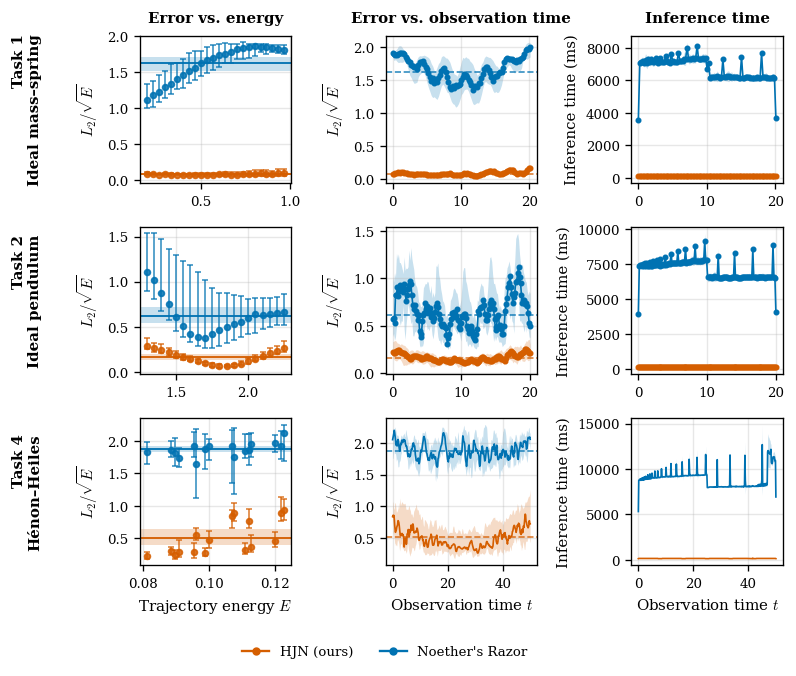

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


saved: /home/thomasdev/Desktop/Hamilton_Jacobi_NN/Hamilton_Jacobi_NN/manuscript_figures/exp1_appendix_high_energy.pdf


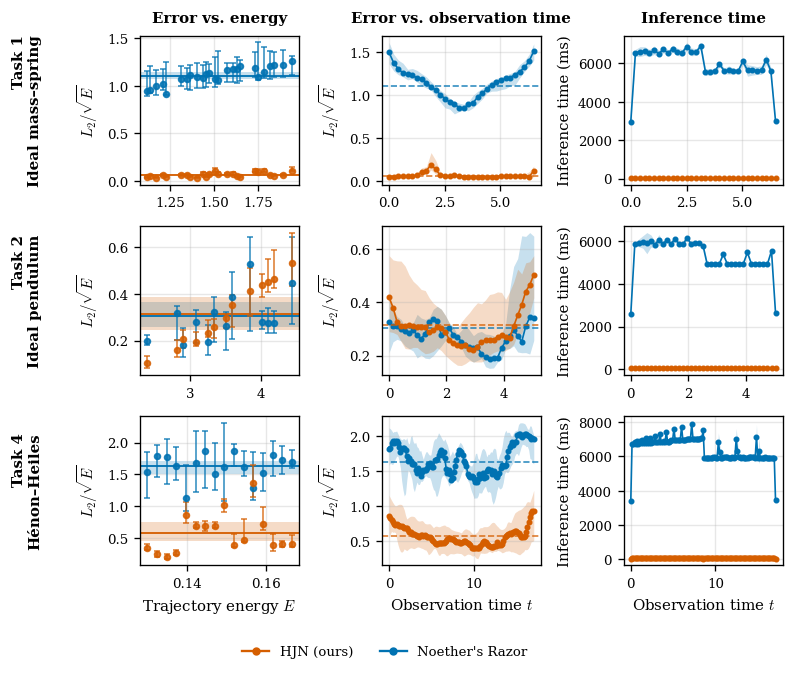

In [6]:
# Main body: temporal extrapolation
fig_main, _ = plot_experiment1_grid('multiple_periods', log_loss=False, log_time=False)
plt.show()

# Appendix: energy extrapolation
fig_app, _ = plot_experiment1_grid('high_energy', log_loss=False, log_time=False)
plt.show()

# If HJN's curve gets squashed near the floor, re-run with log_loss=True:
# plot_experiment1_grid('multiple_periods', log_loss=True)

In [7]:
def print_exp1_numbers(acc=ACC, tim=TIM):
    # row label -> (task, dataset).  A = temporal (multiple_periods), B = energy (high_energy)
    rows = [('T1-A', 1, 'multiple_periods'), ('T1-B', 1, 'high_energy'),
            ('T2-A', 2, 'multiple_periods'), ('T2-B', 2, 'high_energy'),
            ('T4-A', 4, 'multiple_periods'), ('T4-B', 4, 'high_energy')]

    # fairness check: same GPU across methods?
    devs = {TIM[ds][t][m]['timing_stats'].get('device_name')
            for _, t, ds in rows for m in ('HJN', 'Baseline')}
    print("=" * 78)
    print("EXPERIMENT 1 — NUMBERS FOR TABLE 1 (L2/sqrtE, runtime ms, peak GPU mem MB)")
    print("=" * 78)
    print(f"GPU(s) seen across all runs: {devs}")
    if len(devs) > 1:
        print("  !! WARNING: timing runs span different GPUs — not directly comparable.")
    print("CAVEAT: HJN timed in EAGER PyTorch; baseline uses JAX @jit. torch.compile")
    print("        failed (higher-order autograd in forward). Runtime favors baseline.\n")

    latex_rows = []
    for label, t, ds in rows:
        aH, aB = accuracy_stats(acc[ds][t]['HJN']), accuracy_stats(acc[ds][t]['Baseline'])
        tH, tB = timing_stats(tim[ds][t]['HJN']),  timing_stats(tim[ds][t]['Baseline'])

        print(f"----- {label}  (task {t}, {ds}) | N_traj={aH['N_traj']} N_obs={aH['N_obs']} -----")
        for tag, a in (('HJN', aH), ('Base', aB)):
            print(f"  L2/sqrtE {tag:4s}: mean={a['mean']:.4f}  CI=[{a['ci_lo']:.4f}, {a['ci_hi']:.4f}]  "
                  f"median={a['median']:.4f}  IQR=[{a['q1']:.4f}, {a['q3']:.4f}]  std={a['std']:.4f}")
        for tag, T in (('HJN', tH), ('Base', tB)):
            print(f"  runtime  {tag:4s}: {T['mean_ms']:.3f} ms  range=[{T['min_ms']:.3f}, {T['max_ms']:.3f}]  "
                  f"meas_noise={T['meas_noise_ms']:.3f} ms  (n_repeats={T['n_repeats']})")
        for tag, T in (('HJN', tH), ('Base', tB)):
            print(f"  mem(MB)  {tag:4s}: {T['mem_mean']:.1f}  range=[{T['mem_min']:.1f}, {T['mem_max']:.1f}]")
        print()

        latex_rows.append(
            f"{label}\n"
            f"& {aH['mean']:.3f} [{aH['ci_lo']:.3f}, {aH['ci_hi']:.3f}]\n"
            f"& {aB['mean']:.3f} [{aB['ci_lo']:.3f}, {aB['ci_hi']:.3f}]\n"
            f"& {tH['mean_ms']:.2f} [{tH['min_ms']:.2f}, {tH['max_ms']:.2f}]\n"
            f"& {tB['mean_ms']:.2f} [{tB['min_ms']:.2f}, {tB['max_ms']:.2f}]\n"
            f"& {tH['mem_mean']:.1f} [{tH['mem_min']:.1f}, {tH['mem_max']:.1f}]\n"
            f"& {tB['mem_mean']:.1f} [{tB['mem_min']:.1f}, {tB['mem_max']:.1f}]\n\\\\"
        )

    print("=" * 78)
    print("PASTE-READY LaTeX ROWS (column order matches your Table 1)")
    print("=" * 78)
    print("\n\n".join(latex_rows))

print_exp1_numbers()

EXPERIMENT 1 — NUMBERS FOR TABLE 1 (L2/sqrtE, runtime ms, peak GPU mem MB)
GPU(s) seen across all runs: {'NVIDIA GeForce RTX 3060'}
CAVEAT: HJN timed in EAGER PyTorch; baseline uses JAX @jit. torch.compile
        failed (higher-order autograd in forward). Runtime favors baseline.

----- T1-A  (task 1, multiple_periods) | N_traj=24 N_obs=97 -----
  L2/sqrtE HJN : mean=0.0833  CI=[0.0804, 0.0866]  median=0.0825  IQR=[0.0771, 0.0878]  std=0.0079
  L2/sqrtE Base: mean=1.6197  CI=[1.5119, 1.7072]  median=1.7139  IQR=[1.4514, 1.8247]  std=0.2440
  runtime  HJN : 94.288 ms  range=[91.084, 115.139]  meas_noise=1.952 ms  (n_repeats=20)
  runtime  Base: 6713.864 ms  range=[3567.731, 8094.866]  meas_noise=219.522 ms  (n_repeats=20)
  mem(MB)  HJN : 2.8  range=[2.8, 2.8]
  mem(MB)  Base: 0.2  range=[0.2, 0.3]

----- T1-B  (task 1, high_energy) | N_traj=25 N_obs=32 -----
  L2/sqrtE HJN : mean=0.0644  CI=[0.0562, 0.0736]  median=0.0606  IQR=[0.0444, 0.0735]  std=0.0233
  L2/sqrtE Base: mean=1.1086 

In [6]:
import matplotlib.colors as mcolors
from matplotlib.collections import LineCollection

SINGLE_SUB = "prediction_results_single_trajectory"

def _exp2_path(root, task, dataset):
    if task == 3:                                   # Task 3: one file, no dataset variants
        name = "task_3_single_traj_results_test.pkl"
    else:
        name = f"task_{task}_single_traj_results_{dataset}.pkl"
    return root / SINGLE_SUB / name

# (row_label, task, dataset)
EXP2_MAIN_ROWS = [
    (TASK_LABEL[1], 1, 'multiple_periods'),
    (TASK_LABEL[2], 2, 'multiple_periods'),
    (TASK_LABEL[3], 3, 'test'),
    (TASK_LABEL[4], 4, 'multiple_periods'),
]
EXP2_APPENDIX_ROWS = [
    (TASK_LABEL[1], 1, 'high_energy'),
    (TASK_LABEL[2], 2, 'high_energy'),
    (TASK_LABEL[4], 4, 'high_energy'),
]

# HJN's representative trajectory ids (for cross-checking the pickles loaded the right one)
EXPECTED_REP_ID = {
    (1, 'multiple_periods'): 3,  (1, 'high_energy'): 6,
    (2, 'multiple_periods'): 5,  (2, 'high_energy'): 13,
    (3, 'test'): None,
    (4, 'multiple_periods'): 57, (4, 'high_energy'): 10,
}

In [7]:
ROOT = {'HJN': HJN_ROOT, 'Baseline': BASE_ROOT}

def _load_exp2(task, dataset):
    out = {m: _load(_exp2_path(ROOT[m], task, dataset)) for m in ('HJN', 'Baseline')}
    h, b = out['HJN'], out['Baseline']

    # 1) Same physical trajectory id across methods (else energy/phase overlay is meaningless)
    if int(h['trajectory_id']) != int(b['trajectory_id']):
        raise ValueError(
            f"[task{task}/{dataset}] trajectory_id mismatch: "
            f"HJN={h['trajectory_id']} vs Baseline={b['trajectory_id']}. "
            f"Baseline must be evaluated on HJN's representative id.")

    # 2) It is the HJN representative id we expect
    exp = EXPECTED_REP_ID[(task, dataset)]
    if exp is not None and int(h['trajectory_id']) != exp:
        warnings.warn(f"[task{task}/{dataset}] expected rep id {exp}, "
                      f"pickle has {h['trajectory_id']}.")

    # 3) Same ground-truth energy curve (same trajectory, same case)
    if h.get('energy_true') is None or b.get('energy_true') is None:
        raise ValueError(f"[task{task}/{dataset}] missing energy_true in a pickle "
                         f"(was `case` passed for both methods?).")
    if not np.allclose(h['energy_true'], b['energy_true'], atol=1e-5):
        warnings.warn(f"[task{task}/{dataset}] energy_true differs between methods "
                      f"despite matching id — check the data accessor.")
    return out

_pairs = {(t, ds) for _, t, ds in EXP2_MAIN_ROWS + EXP2_APPENDIX_ROWS}
EXP2 = {(t, ds): _load_exp2(t, ds) for (t, ds) in _pairs}

print("Loaded Exp 2 single-trajectory pickles:")
for (t, ds), d in sorted(EXP2.items()):
    h = d['HJN']
    print(f"  task{t}/{ds:16s}: traj_id={h['trajectory_id']:>3}  "
          f"N_obs={h['N']:>3}  T={h['T']:>3}  case={h['case']}")

Loaded Exp 2 single-trajectory pickles:
  task1/high_energy     : traj_id=  6  N_obs= 32  T= 32  case=harmonic_oscillator
  task1/multiple_periods: traj_id=  3  N_obs= 97  T= 97  case=harmonic_oscillator
  task2/high_energy     : traj_id= 13  N_obs= 37  T= 37  case=ideal_pendulum
  task2/multiple_periods: traj_id=  5  N_obs=144  T=144  case=ideal_pendulum
  task3/test            : traj_id=  1  N_obs=112  T=112  case=real_pendulum(constant=2.4)
  task4/high_energy     : traj_id= 10  N_obs=115  T=115  case=henon_heiles(lam=1.0)
  task4/multiple_periods: traj_id= 57  N_obs=334  T=334  case=henon_heiles(lam=1.0)


In [8]:
def exp2_traj_stats(results):
    """Trajectory-level MSE aggregated across obs choices. Median/IQR primary."""
    L = np.asarray(results['per_run_losses'])           # (N,) MSE per obs choice
    q1, q3 = np.percentile(L, 25), np.percentile(L, 75)
    return {'median': float(np.median(L)), 'q1': float(q1), 'q3': float(q3),
            'iqr': float(q3 - q1), 'min': float(L.min()), 'max': float(L.max()),
            'mean': float(L.mean()), 'std': float(np.std(L, ddof=1)),
            'N': results['N'], 'T': results['T']}

def exp2_energy_relerr_obs0(results):
    """Energy fidelity for the displayed obs-0 run only (per the paper text)."""
    Et = np.asarray(results['energy_true'])
    Ep = np.asarray(results['all_energy_pred'])[0]      # obs_idx = 0
    mean_abs = float(np.mean(np.abs(Ep - Et)))
    denom = float(np.mean(np.abs(Et)))
    rel = mean_abs / denom * 100 if denom > 1e-12 else float('nan')
    return {'mean_abs': mean_abs, 'max_abs': float(np.max(np.abs(Ep - Et))),
            'rel_pct': rel}

def _trunc_cmap(name, lo=0.35, hi=1.0, n=256):
    """Drop the near-white low end so light→dark time gradient stays visible."""
    base = plt.get_cmap(name)
    return mcolors.LinearSegmentedColormap.from_list(
        f"{name}_{lo:.2f}_{hi:.2f}", base(np.linspace(lo, hi, n)))

PHASE_CMAP = {'HJN': _trunc_cmap('Oranges'), 'Baseline': _trunc_cmap('Blues')}


def _graded_line(ax, x, y, t, cmap, lw=1.1, alpha=0.95, zorder=3):
    """Draw (x,y) as a polyline coloured by t. Same light->dark encoding as the
    scatter, but readable at hundreds of points."""
    pts  = np.column_stack([np.asarray(x), np.asarray(y)]).reshape(-1, 1, 2)
    segs = np.concatenate([pts[:-1], pts[1:]], axis=1)
    lc = LineCollection(segs, cmap=cmap, lw=lw, alpha=alpha, zorder=zorder)
    lc.set_array(np.asarray(t)[:-1])
    ax.add_collection(lc)
    return lc

In [9]:
def plot_experiment2_grid(rows, *, obs_idx=0,
                          log_error=False, iqr_alpha=0.2,
                          phase_use_colormap=True, phase_show_markers=True,
                          phase_connect=True, phase_marker_size=22,
                          phase_marker_stride=1, phase_dense_cutoff=150,
                          band_alpha=0.18, save=True, fname=None):
    """
    rows: list of (row_label, task, dataset).
    Cols: (1) pointwise SE vs time, median+IQR across obs; (2) energy drift,
    E_true (black) + each method's obs-`obs_idx` E_pred + IQR-across-obs band;
    (3) phase space, truth + each method's obs-`obs_idx` prediction.

    For n>1 tasks column 3 shows ONE canonical pair (q_i, p_i), chosen per task
    by PHASE_PAIR; it is a projection of the 2n-dimensional phase space, not a
    Poincare section. Rows with more than `phase_dense_cutoff` timepoints are
    drawn as time-graded polylines instead of markers (markers blob out at a few
    hundred points); sparser rows keep the original scatter unchanged.
    """
    cfg = FIG_CONFIG
    pw = cfg['text_width_in'] / 3.0
    ph = pw * cfg['panel_aspect']
    nrow = len(rows)
    fig, axes = plt.subplots(nrow, 3, figsize=(3 * pw, nrow * ph), squeeze=False)

    COL_HEADERS = ['Error vs. time', 'Energy drift', 'Phase space']

    for r, (row_label, task, dataset) in enumerate(rows):
        ax_err, ax_en, ax_ph = axes[r]
        d = EXP2[(task, dataset)]

        pi = PHASE_PAIR.get(task, 0)
        ph_xlab, ph_ylab = PHASE_LABELS.get(task, ('$q$', '$p$'))

        # Ground truth is shared across methods (same trajectory)
        ref = d['HJN']
        t   = np.asarray(ref['t'])
        Et  = np.asarray(ref['energy_true'])
        xgt, ugt = _dof(ref['x'], pi), _dof(ref['u'], pi)

        sl    = slice(None, None, max(1, int(phase_marker_stride)))
        dense = len(t) > phase_dense_cutoff

        for m in METHOD_ORDER:                          # baseline first, HJN on top
            c   = PALETTE[m]
            res = d[m]
            pts = res['per_timepoint_stats']

            # ---- Col 1: pointwise SE vs time (median + IQR across obs) ----
            ax_err.fill_between(t, pts['p25'], pts['p75'], color=c, alpha=iqr_alpha, lw=0)
            ax_err.plot(t, pts['median'], '-', lw=1.1, color=c)

            # ---- Col 2: energy drift (obs-idx line + IQR-across-obs band) ----
            es = res['energy_stats']
            Ep0 = np.asarray(res['all_energy_pred'])[obs_idx]
            ax_en.fill_between(t, es['p25'], es['p75'], color=c, alpha=iqr_alpha, lw=0)
            ax_en.plot(t, Ep0, '-', lw=1.1, color=c)

            # ---- Col 3: phase-space projection (obs-idx prediction) ----
            xp = _dof(np.asarray(res['all_x_pred'])[obs_idx], pi)
            up = _dof(np.asarray(res['all_u_pred'])[obs_idx], pi)
            if dense:
                _graded_line(ax_ph, xp, up, t, PHASE_CMAP[m], lw=1.0, alpha=0.9)
            else:
                if phase_connect:
                    ax_ph.plot(xp, up, '-', color=c, alpha=0.30, lw=1.0, zorder=2)
                if phase_show_markers:
                    if phase_use_colormap:
                        ax_ph.scatter(xp[sl], up[sl], c=t[sl], cmap=PHASE_CMAP[m],
                                      s=phase_marker_size, alpha=0.9,
                                      edgecolors='none', zorder=3)
                    else:
                        ax_ph.scatter(xp[sl], up[sl], color=c, s=phase_marker_size,
                                      alpha=0.85, edgecolors='none', zorder=3)
            ax_ph.scatter(xp[0], up[0], color=c, marker='*', s=130,
                          edgecolors='black', linewidths=1.0, zorder=5)

        # Ground truth overlays (drawn last so it reads as the reference)
        ax_en.plot(t, Et, '-', color=PALETTE['Truth'], lw=1.4, zorder=4)

        gt_lw = 0.9 if dense else 1.2
        ax_ph.plot(xgt, ugt, '-', color=PALETTE['Truth'], lw=gt_lw,
                   alpha=0.85 if dense else 0.7, zorder=4)
        if phase_show_markers and not phase_use_colormap and not dense:
            ax_ph.scatter(xgt[sl], ugt[sl], color=PALETTE['Truth'],
                          s=phase_marker_size * 0.7, alpha=0.6,
                          edgecolors='none', zorder=3)
        ax_ph.scatter(xgt[0], ugt[0], color=PALETTE['Truth'], marker='*', s=130,
                      edgecolors='black', linewidths=1.0, zorder=6)
        if dense:
            ax_ph.autoscale_view()      # LineCollection does not autoscale on its own

        if log_error:
            ax_err.set_yscale('log')
            ax_err.set_ylabel('Pointwise SE (log)')
        else:
            ax_err.set_ylabel('Pointwise SE')

        ax_en.set_ylabel('Energy $E$')
        ax_ph.set_ylabel(ph_ylab)
        ax_ph.set_xlabel(ph_xlab)          # per-row: coordinates differ by task
        ax_err.set_xlim(t[0], t[-1]); ax_en.set_xlim(t[0], t[-1])

        if r == nrow - 1:
            ax_err.set_xlabel('Time $t$'); ax_en.set_xlabel('Time $t$')

        # rotated row label
        ax_err.annotate(row_label, xy=(0, 0.5),
                        xytext=(-ax_err.yaxis.labelpad - 16, 0),
                        xycoords=ax_err.yaxis.label, textcoords='offset points',
                        ha='right', va='center', rotation=90,
                        fontsize=cfg['font_size'], fontweight='bold')

    for c_idx, head in enumerate(COL_HEADERS):
        axes[0][c_idx].set_title(head, fontweight='bold', pad=6)

    handles = [Line2D([0], [0], color=PALETTE['HJN'], marker='o', ms=4, lw=1.4, label=METHOD_LABEL['HJN']),
               Line2D([0], [0], color=PALETTE['Baseline'], marker='o', ms=4, lw=1.4, label=METHOD_LABEL['Baseline']),
               Line2D([0], [0], color=PALETTE['Truth'], lw=1.6, label='Ground truth')]
    fig.legend(handles=handles, loc='lower center', ncol=3,
               frameon=False, bbox_to_anchor=(0.5, -0.02))

    fig.tight_layout(rect=(0.03, 0.04, 1, 1))
    if save:
        if fname is None:
            tag = 'main' if any(t == 3 for _, t, _ in rows) else 'appendix'
            sfx = '_logerr' if log_error else ''
            fname = FIG_DIR / f"exp2_{tag}{sfx}.pdf"
        fig.savefig(fname); fig.savefig(Path(fname).with_suffix('.png'))
        print(f"saved: {fname}")
    return fig, axes

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


saved: /home/thomasdev/Desktop/Hamilton_Jacobi_NN/Hamilton_Jacobi_NN/manuscript_figures/exp2_main.pdf


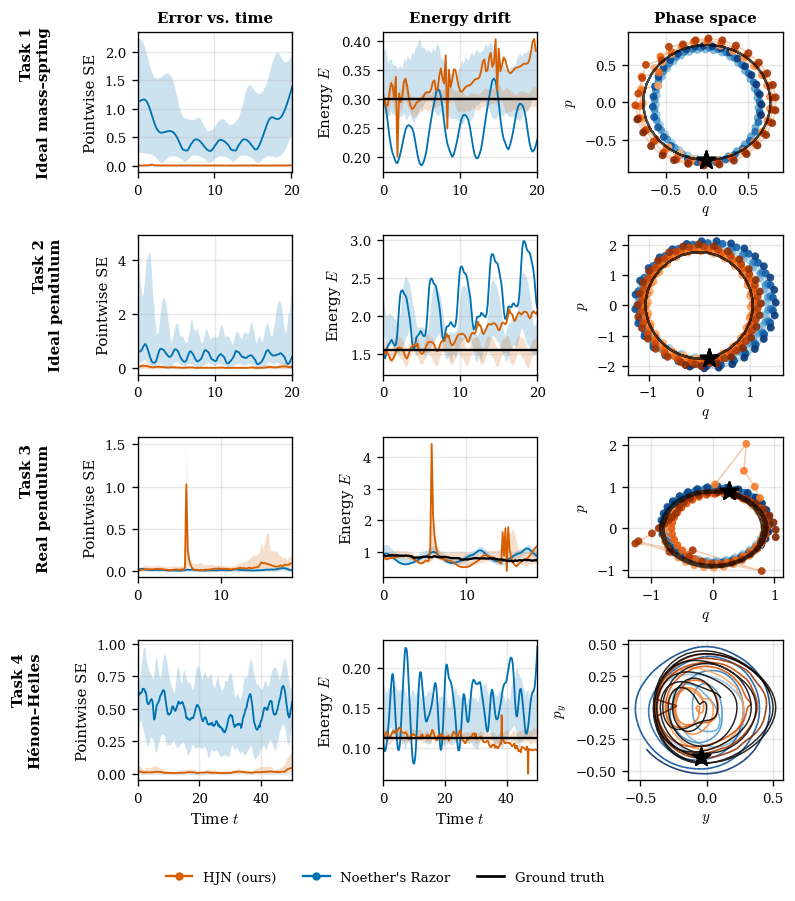

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


saved: /home/thomasdev/Desktop/Hamilton_Jacobi_NN/Hamilton_Jacobi_NN/manuscript_figures/exp2_appendix.pdf


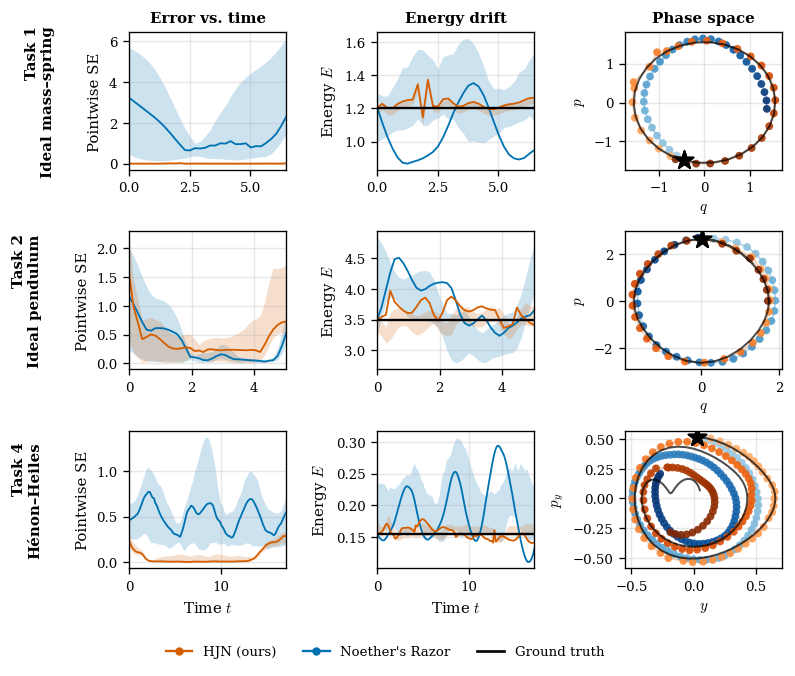

In [10]:
fig2_main, _ = plot_experiment2_grid(EXP2_MAIN_ROWS,
                                     log_error=False, iqr_alpha=0.2,
                                     phase_use_colormap=True)
plt.show()

fig2_app, _ = plot_experiment2_grid(EXP2_APPENDIX_ROWS,
                                    log_error=False, iqr_alpha=0.2,
                                    phase_use_colormap=True)
plt.show()

In [11]:
def print_exp2_numbers():
    rows = [('T1-A', 1, 'multiple_periods'), ('T2-A', 2, 'multiple_periods'),
            ('T3',   3, 'test'),             ('T4-A', 4, 'multiple_periods'),
            ('T1-B', 1, 'high_energy'),      ('T2-B', 2, 'high_energy'),
            ('T4-B', 4, 'high_energy')]
    print("=" * 78)
    print("EXPERIMENT 2 — single-trajectory diagnostics (obs_idx=0 for energy/phase)")
    print("Trajectory-level MSE aggregated across obs choices: median [IQR], range.")
    print("Energy rel. error: obs-0 run only, mean|ΔH|/mean|H_true| × 100.")
    print("=" * 78)
    for label, t, ds in rows:
        d = EXP2[(t, ds)]
        rep = int(d['HJN']['trajectory_id'])
        print(f"\n----- {label} (task {t}, {ds}) | rep traj id={rep} | "
              f"N_obs={d['HJN']['N']} T={d['HJN']['T']} -----")
        for tag, m in (('HJN', 'HJN'), ('Base', 'Baseline')):
            s = exp2_traj_stats(d[m]); e = exp2_energy_relerr_obs0(d[m])
            print(f"  {tag:4s}  MSE median={s['median']:.5f} "
                  f"IQR=[{s['q1']:.5f}, {s['q3']:.5f}] range=[{s['min']:.5f}, {s['max']:.5f}]  "
                  f"(mean={s['mean']:.5f}±{s['std']:.5f})")
            print(f"        energy obs0: mean|ΔH|={e['mean_abs']:.5f}  "
                  f"max|ΔH|={e['max_abs']:.5f}  rel={e['rel_pct']:.2f}%")

print_exp2_numbers()

EXPERIMENT 2 — single-trajectory diagnostics (obs_idx=0 for energy/phase)
Trajectory-level MSE aggregated across obs choices: median [IQR], range.
Energy rel. error: obs-0 run only, mean|ΔH|/mean|H_true| × 100.

----- T1-A (task 1, multiple_periods) | rep traj id=3 | N_obs=97 T=97 -----
  HJN   MSE median=0.00278 IQR=[0.00213, 0.00407] range=[0.00127, 0.01055]  (mean=0.00343±0.00180)
        energy obs0: mean|ΔH|=0.03812  max|ΔH|=0.10314  rel=12.71%
  Base  MSE median=0.70561 IQR=[0.54962, 0.92228] range=[0.33694, 1.44713]  (mean=0.74595±0.28102)
        energy obs0: mean|ΔH|=0.05682  max|ΔH|=0.11390  rel=18.94%

----- T2-A (task 2, multiple_periods) | rep traj id=5 | N_obs=144 T=144 -----
  HJN   MSE median=0.05859 IQR=[0.03845, 0.08935] range=[0.01585, 0.19468]  (mean=0.06947±0.04005)
        energy obs0: mean|ΔH|=0.21221  max|ΔH|=0.53635  rel=13.69%
  Base  MSE median=0.49039 IQR=[0.29000, 3.08570] range=[0.11214, 5.40391]  (mean=1.54071±1.69985)
        energy obs0: mean|ΔH|=0.6009

In [14]:
VAR_SUB = "variance_results"
# Consistency holds for any system whose (alpha, beta) exist along the flow,
# integrable or not — Task 4 (non-integrable) is included deliberately.
EXP3_TASKS = [(1, 'multiple_periods'), (2, 'multiple_periods'), (4, 'multiple_periods')]

def _var_path(root, task, dataset):
    return root / VAR_SUB / f"task_{task}_variance_results_{dataset}.pkl"

# reuse Exp 2's representative ids for narrative continuity
EXP3_PREFER_ID = {(1, 'multiple_periods'): 3,
                  (2, 'multiple_periods'): 5,
                  (4, 'multiple_periods'): 57}

EXP3_ROW_LABEL = TASK_LABEL

# colors for the per-quantity traces — deliberately NOT the method colors.
QUANT_COLORS = ['#1B9E77', '#7570B3', '#D95F02', '#E7298A', '#66A61E']

In [15]:
def _rep_index(var_res, prefer_id=None, acc_res=None, strict=True):
    """Return (row_index, trajectory_id, how_selected)."""
    final = var_res['variance_avg'][-1, :]
    ids = None
    if acc_res is not None:
        ids_arr = np.asarray(acc_res['trajectory_ids']).astype(int)
        if len(ids_arr) == var_res['N_traj']:
            ids = ids_arr
    if prefer_id is not None:
        if ids is not None:
            hit = np.where(ids == int(prefer_id))[0]
            if len(hit) == 1:
                return int(hit[0]), int(prefer_id), f'preferred id={prefer_id} (matches Exp 2)'
        if strict:
            raise ValueError(
                f"Exp-3 preferred trajectory id {prefer_id} could not be located "
                f"(ids available: {ids is not None}). The figure caption claims the "
                f"Exp-2 representative is shown, so falling back to a different rule "
                f"would falsify it. Fix the id or pass strict=False deliberately.")
    med = np.nanmedian(final)
    idx = int(np.nanargmin(np.abs(final - med)))
    tid = int(ids[idx]) if ids is not None else None
    return idx, tid, 'closest-to-median full-obs CV'

def _global_cv(curve, eps=1e-3):
    """Per-DOF global-horizon CV. Returns a list of length n."""
    c = _dof2d(np.asarray(curve))                       # (T, n)
    return [float(c[:, i].std(ddof=1) / (abs(c[:, i].mean()) + eps))
            for i in range(c.shape[1])]

def _fmt(vals):
    return ', '.join(f'{v:.3f}' for v in vals)

VAR = {}
for (t, ds) in EXP3_TASKS:
    h = _load(_var_path(HJN_ROOT,  t, ds))
    b = _load(_var_path(BASE_ROOT, t, ds))
    acc_res = ACC.get(ds, {}).get(t, {}).get('HJN')
    rep, tid, how = _rep_index(h, EXP3_PREFER_ID.get((t, ds)), acc_res)
    VAR[(t, ds)] = {'HJN': h, 'Baseline': b,
                    'rep_idx': rep, 'rep_id': tid, 'rep_how': how}
    if not (0 <= rep < b['N_traj']):
        raise ValueError(f"rep idx {rep} out of range for baseline (N={b['N_traj']})")

print("Exp 3 loaded:")
for (t, ds), d in VAR.items():
    h, b, rep = d['HJN'], d['Baseline'], d['rep_idx']
    print(f"\n--- task{t}/{ds} | rep row={rep} traj_id={d['rep_id']} "
          f"({d['rep_how']}) | N_traj={h['N_traj']} N_obs={h['N_obs']} K_base={b['K']} ---")
    print(f"  HJN  within-seg CV (full obs): median={h['final_median']:.4f} "
          f"IQR=[{h['final_q1']:.4f}, {h['final_q3']:.4f}]  "
          f"CI({h['ci_method']})=[{h['final_ci_lower']:.4f}, {h['final_ci_upper']:.4f}]")
    print(f"  Base within-seg CV (full obs): median={b['final_median']:.4f} "
          f"IQR=[{b['final_q1']:.4f}, {b['final_q3']:.4f}]  "
          f"CI({b['ci_method']})=[{b['final_ci_lower']:.4f}, {b['final_ci_upper']:.4f}]")
    hq = _global_cv(h['X_final_array'][rep]); hp = _global_cv(h['U_final_array'][rep])
    bc = [_global_cv(b['C_array'][rep, k])[0] for k in range(b['K'])]
    print(f"  rep global-horizon CV  HJN: Q={_fmt(hq)}  P={_fmt(hp)}  "
          f"(expected high — coords reset each Tmax)")
    print(f"  rep global-horizon CV  Base C_k: {_fmt(bc)}  "
          f"(claimed globally invariant — should be LOW if claim holds)")

Exp 3 loaded:

--- task1/multiple_periods | rep row=3 traj_id=3 (preferred id=3 (matches Exp 2)) | N_traj=24 N_obs=97 K_base=3 ---
  HJN  within-seg CV (full obs): median=0.0135 IQR=[0.0101, 0.0154]  CI(BCa)=[0.0117, 0.0148]
  Base within-seg CV (full obs): median=0.4038 IQR=[0.3841, 0.4338]  CI(BCa)=[0.3858, 0.4298]
  rep global-horizon CV  HJN: Q=0.053  P=0.068  (expected high — coords reset each Tmax)
  rep global-horizon CV  Base C_k: 0.589, 0.465, 0.556  (claimed globally invariant — should be LOW if claim holds)

--- task2/multiple_periods | rep row=5 traj_id=5 (preferred id=5 (matches Exp 2)) | N_traj=20 N_obs=144 K_base=3 ---
  HJN  within-seg CV (full obs): median=0.0701 IQR=[0.0289, 0.2100]  CI(BCa)=[0.0308, 0.1581]
  Base within-seg CV (full obs): median=0.7425 IQR=[0.7291, 0.7640]  CI(BCa)=[0.7298, 0.7623]
  rep global-horizon CV  HJN: Q=0.115  P=0.261  (expected high — coords reset each Tmax)
  rep global-horizon CV  Base C_k: 0.470, 0.946, 0.858  (claimed globally invaria

In [16]:
def plot_experiment3_grid(*, rep_id_override=None, log_cv=False,
                          iqr_alpha=0.22, band_alpha=0.22, trace_lw=1.1,
                          save=True, fname=None):
    """
    rep_id_override: dict {(task,dataset): trajectory_id} to force a trajectory.
    Selection (default + any override) is reported via print, not drawn.
    Col 1 shows all 2n learned coordinates: colour = DOF index, solid = Q,
    dashed = P (reduces to a single Q/P pair at n = 1).
    """
    cfg = FIG_CONFIG
    pw = cfg['text_width_in'] / 3.0
    ph = pw * cfg['panel_aspect']
    rows = EXP3_TASKS
    fig, axes = plt.subplots(len(rows), 3, figsize=(3 * pw, len(rows) * ph), squeeze=False)
    COL_HEADERS = ['HJN coords $(Q,P)$', 'Baseline invariants $C_k$',
                   'Within-segment CV']

    sel_report = []

    def _traces(ax, t_arr, curves, names, Tmax, horizon, legend_loc,
                colors=None, styles=None, ncol=None):
        for j, (curve, nm) in enumerate(zip(curves, names)):
            ax.plot(t_arr, curve,
                    styles[j] if styles else '-', lw=trace_lw,
                    color=(colors[j] if colors else QUANT_COLORS[j % len(QUANT_COLORS)]),
                    label=nm)
        m = Tmax
        while m < horizon - 1e-9:
            ax.axvline(m, color='0.4', ls='--', lw=0.7, alpha=0.7)
            m += Tmax
        ax.set_xlim(t_arr[0], t_arr[-1])
        ax.legend(fontsize=cfg['legend_size'] - 1, loc=legend_loc,
                  ncol=(ncol or len(names)), columnspacing=0.8, handlelength=1.2,
                  borderaxespad=0.3, framealpha=0.65)

    for r, (t, ds) in enumerate(rows):
        ax_q, ax_c, ax_v = axes[r]
        d = VAR[(t, ds)]
        h, b = d['HJN'], d['Baseline']

        rep, tid, how = d['rep_idx'], d['rep_id'], d['rep_how']
        if rep_id_override and (t, ds) in rep_id_override:
            want = int(rep_id_override[(t, ds)])
            acc_res = ACC.get(ds, {}).get(t, {}).get('HJN')
            ids = np.asarray(acc_res['trajectory_ids']).astype(int) if acc_res else None
            if ids is not None and len(ids) == h['N_traj'] and (ids == want).sum() == 1:
                rep = int(np.where(ids == want)[0][0]); tid = want; how = 'manual override'
            else:
                warnings.warn(f"override id {want} not found for task{t}/{ds}; keeping default")
        sel_report.append((t, ds, tid, rep, how))

        t_arr = np.asarray(h['t']); Tmax = h['Tmax']; horizon = t_arr[-1]

        # ---- col 1: all 2n learned coordinates ----
        Xr, Ur = _dof2d(h['X_final_array'][rep]), _dof2d(h['U_final_array'][rep])
        nd = Xr.shape[1]
        if nd == 1:
            curves = [Xr[:, 0], Ur[:, 0]]
            names  = ['$Q$', '$P$']
            colors = [QUANT_COLORS[0], QUANT_COLORS[1]]
            styles = ['-', '-']
        else:
            curves = [Xr[:, i] for i in range(nd)] + [Ur[:, i] for i in range(nd)]
            names  = ([f'$Q_{{{i+1}}}$' for i in range(nd)] +
                      [f'$P_{{{i+1}}}$' for i in range(nd)])
            colors = ([QUANT_COLORS[i % len(QUANT_COLORS)] for i in range(nd)] * 2)
            styles = ['-'] * nd + ['--'] * nd
        _traces(ax_q, t_arr, curves, names, Tmax, horizon,
                legend_loc='lower right', colors=colors, styles=styles,
                ncol=min(len(names), 2))
        ax_q.set_ylabel('Learned coord.')

        # ---- col 2: baseline invariants ----
        _traces(ax_c, t_arr, [b['C_array'][rep, k] for k in range(b['K'])],
                [f'$C_{{{k+1}}}$' for k in range(b['K'])], Tmax, horizon,
                legend_loc='lower center', ncol=b['K'])
        ax_c.set_ylabel('Learned invariant')

        # ---- col 3: CV curve, both methods ----
        for m, res in (('HJN', h), ('Baseline', b)):
            c = PALETTE[m]; vm = res['valid_mask']
            xp = res['point_counts'][vm]
            ax_v.fill_between(xp, res['p25_curve'][vm], res['p75_curve'][vm],
                              color=c, alpha=band_alpha, lw=0)
            ax_v.plot(xp, res['median_curve'][vm], '-', lw=1.2, color=c)
        if log_cv:
            ax_v.set_yscale('log'); ax_v.set_ylabel('Within-segment CV (log)')
        else:
            ax_v.set_ylabel('Within-segment CV')

        if r == len(rows) - 1:
            ax_q.set_xlabel('Time $t$'); ax_c.set_xlabel('Time $t$')
            ax_v.set_xlabel('Sampled points / traj.')

        ax_q.annotate(EXP3_ROW_LABEL[t], xy=(0, 0.5),
                      xytext=(-ax_q.yaxis.labelpad - 16, 0),
                      xycoords=ax_q.yaxis.label, textcoords='offset points',
                      ha='right', va='center', rotation=90,
                      fontsize=cfg['font_size'], fontweight='bold')

    for c_idx, head in enumerate(COL_HEADERS):
        axes[0][c_idx].set_title(head, fontweight='bold', pad=6)

    handles = [Line2D([0], [0], color=PALETTE['HJN'], lw=1.6, label=METHOD_LABEL['HJN']),
               Line2D([0], [0], color=PALETTE['Baseline'], lw=1.6, label=METHOD_LABEL['Baseline'])]
    fig.legend(handles=handles, loc='lower center', ncol=2,
               frameon=False, bbox_to_anchor=(0.5, -0.02))

    fig.tight_layout(rect=(0.04, 0.04, 1, 1))

    print("Representative trajectory selection (Exp 3):")
    print("  Rule: the Exp-2 representative id (required, not optional).")
    for (t, ds, tid, row, how) in sel_report:
        print(f"  task{t}/{ds}: traj_id={tid} (matrix row {row}) — {how}")

    if save:
        if fname is None:
            sfx = '_logcv' if log_cv else ''
            fname = FIG_DIR / f"exp3_main{sfx}.pdf"
        fig.savefig(fname); fig.savefig(Path(fname).with_suffix('.png'))
        print(f"saved: {fname}")
    return fig, axes

Representative trajectory selection (Exp 3):
  Rule: the Exp-2 representative id (required, not optional).
  task1/multiple_periods: traj_id=3 (matrix row 3) — preferred id=3 (matches Exp 2)
  task2/multiple_periods: traj_id=5 (matrix row 5) — preferred id=5 (matches Exp 2)
  task4/multiple_periods: traj_id=57 (matrix row 6) — preferred id=57 (matches Exp 2)


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


saved: /home/thomasdev/Desktop/Hamilton_Jacobi_NN/Hamilton_Jacobi_NN/manuscript_figures/exp3_main.pdf


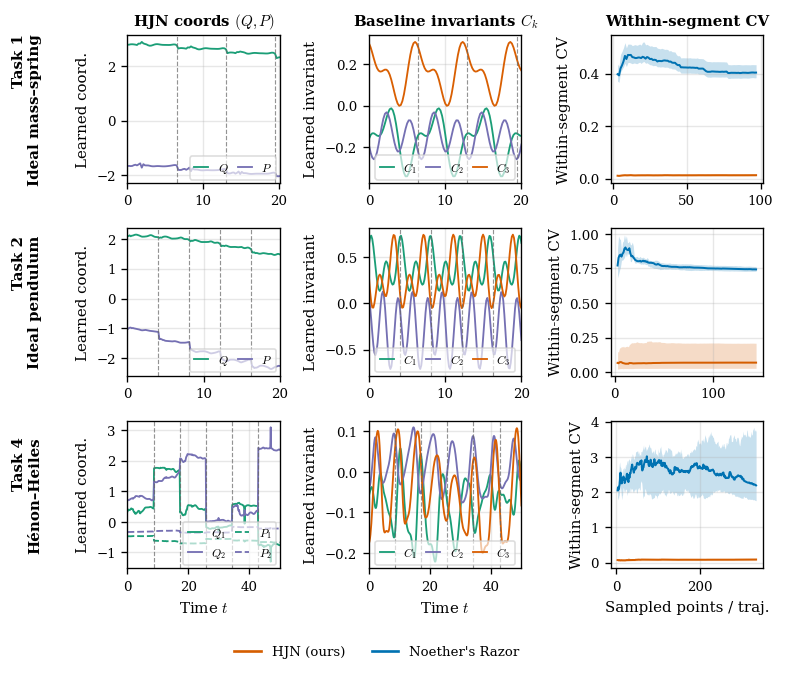

In [17]:
fig3, _ = plot_experiment3_grid(log_cv=False, iqr_alpha=0.22)
plt.show()
# if the CV curves differ by an order of magnitude and squash, try:
# plot_experiment3_grid(log_cv=True)

In [18]:
def print_exp3_numbers():
    print("=" * 78)
    print("EXPERIMENT 3 — within-segment consistency at FULL observation")
    print("Metric: per-segment mean CV of conserved quantities, median[IQR] over trajectories")
    print("(order-independent at full obs; CI is BCa unless fallback noted)")
    print("=" * 78)
    rows = []
    for (t, ds) in EXP3_TASKS:
        d = VAR[(t, ds)]
        for tag, m in (('HJN', 'HJN'), ('Base', 'Baseline')):
            r = d[m]
            print(f"  T{t}  {tag:4s}: median={r['final_median']:.4f}  "
                  f"IQR=[{r['final_q1']:.4f}, {r['final_q3']:.4f}]  "
                  f"CI({r['ci_method']})=[{r['final_ci_lower']:.4f}, {r['final_ci_upper']:.4f}]")
        h, b = d['HJN'], d['Baseline']
        rows.append(
            f"T{t}\n"
            f"& {h['final_median']:.4f} [{h['final_q1']:.4f}, {h['final_q3']:.4f}]\n"
            f"& {b['final_median']:.4f} [{b['final_q1']:.4f}, {b['final_q3']:.4f}]\n\\\\")
        print()
    print("=" * 78)
    print("PASTE-READY LaTeX ROWS (Task | HJN CV | Base CV)")
    print("=" * 78)
    print("\n\n".join(rows))

print_exp3_numbers()

EXPERIMENT 3 — within-segment consistency at FULL observation
Metric: per-segment mean CV of conserved quantities, median[IQR] over trajectories
(order-independent at full obs; CI is BCa unless fallback noted)
  T1  HJN : median=0.0135  IQR=[0.0101, 0.0154]  CI(BCa)=[0.0117, 0.0148]
  T1  Base: median=0.4038  IQR=[0.3841, 0.4338]  CI(BCa)=[0.3858, 0.4298]

  T2  HJN : median=0.0701  IQR=[0.0289, 0.2100]  CI(BCa)=[0.0308, 0.1581]
  T2  Base: median=0.7425  IQR=[0.7291, 0.7640]  CI(BCa)=[0.7298, 0.7623]

  T4  HJN : median=0.0892  IQR=[0.0582, 0.1085]  CI(BCa)=[0.0618, 0.1088]
  T4  Base: median=2.1903  IQR=[1.7585, 3.7703]  CI(BCa)=[1.7809, 3.6319]

PASTE-READY LaTeX ROWS (Task | HJN CV | Base CV)
T1
& 0.0135 [0.0101, 0.0154]
& 0.4038 [0.3841, 0.4338]
\\

T2
& 0.0701 [0.0289, 0.2100]
& 0.7425 [0.7291, 0.7640]
\\

T4
& 0.0892 [0.0582, 0.1085]
& 2.1903 [1.7585, 3.7703]
\\


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


saved: manuscript_figures/energy_recovery_time_shift_both_tasks.pdf


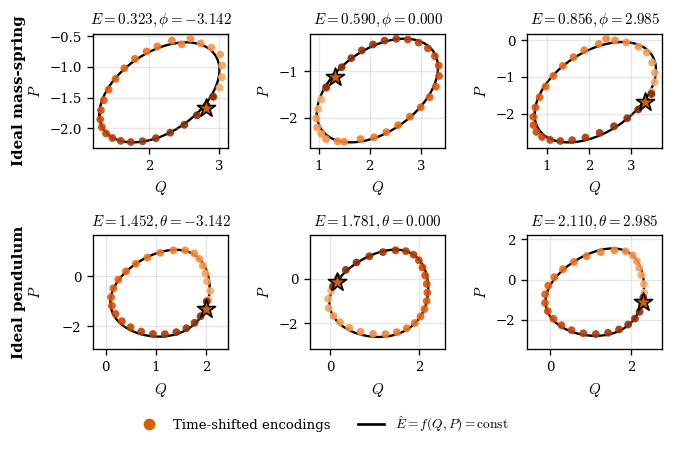

In [8]:
# ============================================================
# Energy recovery time-shift figure: Mass-Spring + Pendulum
# Loads:
#   ./conserved_quantities_results/mass_spring_results.pkl
#   ./conserved_quantities_results/pendulum_results.pkl
#
# Saves:
#   ./manuscript_figures/energy_recovery_time_shift_both_tasks.pdf
#   ./manuscript_figures/energy_recovery_time_shift_both_tasks.png
# ============================================================

import pickle
from pathlib import Path

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D


# ------------------------------------------------------------------
# Styling (same as your mass-spring figure)
# ------------------------------------------------------------------
PALETTE = {
    'HJN':      '#D55E00',
    'Baseline': '#0072B2',
    'Truth':    '#000000',
}

FIG_CONFIG = {
    'text_width_in': 6.9,
    'panel_aspect': 0.80,
    'font_size': 9,
    'tick_size': 8,
    'legend_size': 8,
    'use_tex': False,
    'font_family': 'serif',
}

def apply_style(cfg=FIG_CONFIG):
    mpl.rcParams.update({
        'pdf.fonttype': 42,
        'ps.fonttype': 42,
        'savefig.dpi': 300,
        'figure.dpi': 120,
        'savefig.bbox': 'tight',
        'font.size': cfg['font_size'],
        'axes.titlesize': cfg['font_size'],
        'axes.labelsize': cfg['font_size'],
        'xtick.labelsize': cfg['tick_size'],
        'ytick.labelsize': cfg['tick_size'],
        'legend.fontsize': cfg['legend_size'],
        'axes.grid': True,
        'grid.alpha': 0.3,
        'axes.linewidth': 0.8,
        'lines.linewidth': 1.2,
        'font.family': cfg['font_family'],
        'text.usetex': cfg['use_tex'],
        'mathtext.fontset': 'cm',
    })

def _trunc_cmap(name, lo=0.35, hi=1.0, n=256):
    base = plt.get_cmap(name)
    return mcolors.LinearSegmentedColormap.from_list(
        f"{name}_{lo:.2f}_{hi:.2f}",
        base(np.linspace(lo, hi, n))
    )

PHASE_CMAP = _trunc_cmap('Oranges')

apply_style()


# ------------------------------------------------------------------
# Load pickles
# ------------------------------------------------------------------
with open(
    "./conserved_quantities_results/mass_spring_results.pkl",
    "rb"
) as f:
    ms = pickle.load(f)

with open(
    "./conserved_quantities_results/pendulum_results.pkl",
    "rb"
) as f:
    pend = pickle.load(f)


# ------------------------------------------------------------------
# Unpack mass-spring
# ------------------------------------------------------------------
res_train_ms      = ms["res_train"]
Q_full_ms         = ms["Q_full"]
P_full_ms         = ms["P_full"]
taus_ms           = ms["taus"]
closest_ms        = ms["closest_indices"]
COEFFS            = ms["COEFFS"]

# ------------------------------------------------------------------
# Unpack pendulum
# ------------------------------------------------------------------
res_train_pd      = pend["res_train"]
ts_pd             = pend["ts"]
closest_pd        = pend["closest_indices"]
readouts_pd       = pend["readouts"]

Q_full_pd         = ts_pd["Q_full"]
P_full_pd         = ts_pd["P_full"]
taus_pd           = ts_pd["taus"]

energy_degree_pd  = pend.get("energy_degree", 3)
model_pd          = readouts_pd["energy"][energy_degree_pd]


# ------------------------------------------------------------------
# Figure layout
# ------------------------------------------------------------------
pw = FIG_CONFIG['text_width_in'] / 3.0
ph = pw * FIG_CONFIG['panel_aspect']

fig, axes = plt.subplots(
    2,
    3,
    figsize=(3 * pw, 2 * ph),
    squeeze=False
)

# Row labels anchored to the leftmost axes (axes-fraction coords),
# so they follow the panels through any tight_layout reflow.
for r, label in enumerate(["Ideal mass-spring", "Ideal pendulum"]):
    axes[r, 0].text(
        -0.55, 0.5, label,
        transform=axes[r, 0].transAxes,
        rotation=90,
        va="center",
        ha="center",
        fontsize=FIG_CONFIG["font_size"],
        fontweight="bold",
    )


# ============================================================
# FIRST ROW : MASS SPRING
# ============================================================
for ax, idx in zip(axes[0], closest_ms):

    Ec = float(res_train_ms["E"][idx])
    phi = float(res_train_ms["phi"][idx])

    c_const = COEFFS['c_const']
    a       = COEFFS['a']
    b       = COEFFS['b']
    c_quad  = COEFFS['c_quad']
    d       = COEFFS['d']
    e       = COEFFS['e']

    A_q = d**2 - 4 * e * c_quad
    B_q = -2 * b * d + 4 * e * a
    C_q = b**2 - 4 * e * (c_const - Ec)

    disc_q = B_q**2 - 4 * A_q * C_q

    q1 = (-B_q + np.sqrt(disc_q)) / (2 * A_q)
    q2 = (-B_q - np.sqrt(disc_q)) / (2 * A_q)

    qmin, qmax = min(q1, q2), max(q1, q2)

    Q_vals = np.linspace(qmin, qmax, 1000)

    valid_Q = []
    valid_P1 = []
    valid_P2 = []

    for Q in Q_vals:

        A = e
        B = b - d * Q
        C = c_quad * Q**2 - a * Q + c_const - Ec

        disc = max(0, B**2 - 4 * A * C)

        valid_Q.append(Q)
        valid_P1.append((-B + np.sqrt(disc)) / (2 * A))
        valid_P2.append((-B - np.sqrt(disc)) / (2 * A))

    Q_contour = valid_Q + valid_Q[::-1]
    P_contour = valid_P1 + valid_P2[::-1]

    ax.plot(
        Q_contour,
        P_contour,
        color=PALETTE['Truth'],
        lw=1.4,
        zorder=1
    )

    xp = Q_full_ms[:, idx]
    up = P_full_ms[:, idx]

    ax.scatter(
        xp,
        up,
        c=taus_ms,
        cmap=PHASE_CMAP,
        s=22,
        alpha=0.9,
        edgecolors='none',
        zorder=3
    )

    ax.scatter(
        xp[0],
        up[0],
        color=PALETTE['HJN'],
        marker='*',
        s=130,
        edgecolors='black',
        linewidths=1.0,
        zorder=5
    )

    ax.set_title(
        rf"$E={Ec:.3f},\phi={phi:.3f}$",
        fontweight='bold'
    )

    ax.set_xlabel(r"$Q$")
    ax.set_ylabel(r"$P$")


# ============================================================
# SECOND ROW : PENDULUM
# ============================================================
for ax, idx in zip(axes[1], closest_pd):

    Ec = float(res_train_pd["E"][idx])
    theta = float(res_train_pd["phi"][idx])

    xp = Q_full_pd[:, idx]
    up = P_full_pd[:, idx]

    qmin, qmax = xp.min(), xp.max()
    pmin, pmax = up.min(), up.max()

    dq = (qmax - qmin) or 1.0
    dp = (pmax - pmin) or 1.0

    qs = np.linspace(qmin - 0.18*dq, qmax + 0.18*dq, 300)
    ps = np.linspace(pmin - 0.18*dp, pmax + 0.18*dp, 300)

    QQ, PP = np.meshgrid(qs, ps)

    EE = model_pd.predict(
        np.column_stack([QQ.ravel(), PP.ravel()])
    ).reshape(QQ.shape)

    ax.contour(
        QQ,
        PP,
        EE,
        levels=[Ec],
        colors='k',
        linewidths=1.4,
        zorder=1
    )

    ax.scatter(
        xp,
        up,
        c=taus_pd,
        cmap=PHASE_CMAP,
        s=22,
        alpha=0.9,
        edgecolors='none',
        zorder=3
    )

    ax.scatter(
        xp[0],
        up[0],
        color=PALETTE['HJN'],
        marker='*',
        s=130,
        edgecolors='black',
        linewidths=1.0,
        zorder=5
    )

    ax.set_title(
        rf"$E={Ec:.3f},\theta={theta:.3f}$",
        fontweight='bold'
    )

    ax.set_xlabel(r"$Q$")
    ax.set_ylabel(r"$P$")


# ------------------------------------------------------------------
# Shared legend
# ------------------------------------------------------------------
handles = [
    Line2D(
        [0], [0],
        color=PALETTE['HJN'],
        marker='o',
        lw=0,
        label='Time-shifted encodings'
    ),
    Line2D(
        [0], [0],
        color=PALETTE['Truth'],
        lw=1.6,
        label=r'$\hat{E}=f(Q,P)=\mathrm{const}$'
    ),
]

fig.legend(
    handles=handles,
    loc='lower center',
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.57, -0.02)
)

fig.align_ylabels()

fig.tight_layout(rect=(0.14, 0.05, 1, 1))


# ------------------------------------------------------------------
# Save
# ------------------------------------------------------------------
FIG_DIR = Path("./manuscript_figures")
FIG_DIR.mkdir(exist_ok=True)

fname = FIG_DIR / "energy_recovery_time_shift_both_tasks.pdf"

fig.savefig(fname)
fig.savefig(fname.with_suffix(".png"))

print(f"saved: {fname}")

plt.show()

In [16]:
# ======================================================================
# EXPERIMENT 4 — frame sweep / HSIC detector: config
# ======================================================================
import pandas as pd

# Colours for the sweep arms. Okabe-Ito, deliberately NOT reusing the
# method colours from PALETTE (there are no competing methods here).
ARM_COLORS  = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
ARM_MARKERS = ['o', 's', '^', 'v', 'D', 'P']

# The sweep pickle was saved with a relative path; resolve it here.
FRAME_CANDIDATES = [
    HJN_ROOT / "frame_sweep_res.pkl",
    HJN_ROOT / "frame_sweep_outputs" / "frame_sweep_res.pkl",
    Path.cwd() / "frame_sweep_res.pkl",
]

def _resolve_frame_path(candidates=FRAME_CANDIDATES):
    for p in candidates:
        if p.exists():
            print(f"frame sweep pickle: {p}")
            return p
    raise FileNotFoundError(
        "frame_sweep_res.pkl not found. Tried:\n  "
        + "\n  ".join(str(p) for p in candidates)
        + "\nRun this in a terminal to locate it:\n"
          "  find ~/Desktop -name 'frame_sweep_res.pkl' 2>/dev/null")

FRAME_PATH = _resolve_frame_path()

frame sweep pickle: /home/thomasdev/Desktop/Hamilton_Jacobi_NN/Hamilton_Jacobi_NN/frame_sweep_res.pkl


In [17]:
# ======================================================================
# EXPERIMENT 4 — load
# ======================================================================
# The pickle holds float32/float64 prediction tensors as well as the
# results table. Only 'df' and 'checks' are used downstream, but pickle
# rebuilds every object it stored, so `torch` must be importable here.
try:
    with open(FRAME_PATH, "rb") as f:
        FRAME = pickle.load(f)
except ModuleNotFoundError as e:
    raise ModuleNotFoundError(
        f"{e}\n\nThe sweep pickle contains torch tensors (preds32/preds64), so "
        f"unpickling needs torch in this kernel. Either install it here, or "
        f"re-save a slim pickle from the sweep notebook:\n"
        f"    slim = {{'df': res['df'], 'checks': res['checks']}}\n"
        f"    pickle.dump(slim, open('frame_sweep_slim.pkl','wb'))\n"
        f"and point FRAME_CANDIDATES at that file instead.") from e

_fd = FRAME['df']
print(f"Loaded frame sweep: {len(_fd)} sweep points, "
      f"arms={list(dict.fromkeys(_fd['arm_label']))}")
print(f"  columns present: r64={'r64' in _fd.columns}  "
      f"e_num_mean={'e_num_mean' in _fd.columns}")
print(f"  checks: symplecticity_pass={FRAME['checks'].get('sigma_pairing_pass')}  "
      f"max|r64-1|={FRAME['checks'].get('r64_max_dev', float('nan')):.3e}")

Loaded frame sweep: 46 sweep points, arms=['squeeze', 'shear', 'rotate $a_0$=100', 'rotate $a_0$=1000', 'rotate $a_0$=10000']
  columns present: r64=True  e_num_mean=True
  checks: symplecticity_pass=True  max|r64-1|=3.462e-08


In [18]:
def detector_summary(res, r32_tol=0.01, skeel_mult=10.0, enum_mult=2.0,
                     verbose=True):
    """
    Thresholds are set from the identity frame S = I and never from HSIC,
    so the detector claim is not circular.
    """
    df = res['df']
    ch = res['checks']
    floor = enum_mult * ch['e_num_identity']
    skeel_thr = skeel_mult * ch['skeel_identity']
    fires = df['hsic'] > 1e-9
    links = {
        'L1 conditioning': df['skeel_med'] > skeel_thr,
        'L2 float amplification': df['e_num_mean'] > floor,
        'L3 practical impact': (df['r32'] - 1.0).abs() > r32_tol,
    }
    if verbose:
        print(f"thresholds from S=I: Skeel > {skeel_thr:.3g}, "
              f"e_num > {floor:.3g}, |r32-1| > {r32_tol:g}\n")
    out = {}
    for name, harmful in links.items():
        fn = int((~fires & harmful).sum())
        out[name] = dict(n_harmful=int(harmful.sum()), false_negatives=fn,
                         fires_early=int((fires & ~harmful).sum()))
        if verbose:
            print(f"{name:24s}  harmful {harmful.sum():2d}/{len(df)}  "
                  f"missed by HSIC: {fn}  (fires before onset: "
                  f"{out[name]['fires_early']})")
    silent = df[~fires]
    out['n_silent'] = int(len(silent))
    out['silent_max_enum'] = float(silent['e_num_mean'].max())
    out['silent_max_r32_dev'] = float((silent['r32'] - 1.0).abs().max())
    out['silent_kappa_range'] = (float(silent['kappa_med'].min()),
                                 float(silent['kappa_med'].max()))
    out['firing_hsic_range'] = (float(df.loc[fires, 'hsic'].min()),
                                float(df.loc[fires, 'hsic'].max()))
    if verbose:
        print(f"\nHSIC exactly 0 on {out['n_silent']}/{len(df)} frames.")
        print(f"  those span kappa [{out['silent_kappa_range'][0]:.2e}, "
              f"{out['silent_kappa_range'][1]:.2e}]")
        print(f"  max e_num among them   : {out['silent_max_enum']:.3e}")
        print(f"  max |r32 - 1| among them: {out['silent_max_r32_dev']:.3e}")
        print(f"HSIC when firing: [{out['firing_hsic_range'][0]:.4f}, "
              f"{out['firing_hsic_range'][1]:.4f}]")


    # kappa as null control: it is neither necessary nor sufficient
    sq = df[df['kind'] == 'squeeze']
    out['kappa_null'] = dict(
        squeeze_kappa_range=(float(sq['kappa_med'].min()), float(sq['kappa_med'].max())),
        squeeze_skeel_range=(float(sq['skeel_med'].min()), float(sq['skeel_med'].max())),
        squeeze_max_hsic=float(sq['hsic'].max()),
        squeeze_max_r32_dev=float((sq['r32'] - 1.0).abs().max()),
    )
    for arm in df.loc[df['kind'] == 'rotate', 'arm'].unique():
        s = df[df['arm'] == arm]
        out['kappa_null'][f'{arm}_r32_range'] = (float(s['r32'].min()),
                                                 float(s['r32'].max()))
    if verbose:
        kn = out['kappa_null']
        print(f"\nkappa null control:")
        print(f"  squeeze: kappa {kn['squeeze_kappa_range'][0]:.2e} -> "
              f"{kn['squeeze_kappa_range'][1]:.2e} ({np.log10(kn['squeeze_kappa_range'][1]/kn['squeeze_kappa_range'][0]):.0f} decades), "
              f"Skeel constant at {kn['squeeze_skeel_range'][0]:.6f}")
        print(f"  squeeze: max HSIC {kn['squeeze_max_hsic']:.3e}, "
              f"max |r32-1| {kn['squeeze_max_r32_dev']:.3e}")
        for arm in df.loc[df['kind'] == 'rotate', 'arm'].unique():
            lo, hi = kn[f'{arm}_r32_range']
            print(f"  {arm}: kappa pinned, r32 in [{lo:.3f}, {hi:.3f}]")
    return out


def paper_table(res, latex=True):
    """Benign block then harmful block, theta in degrees."""
    df = res['df'].set_index('key')
    benign = ['squeeze|1', 'squeeze|100000', 'rotate10000|0', 'rotate10000|90deg']
    harmful = ['rotate10000|1e-06', 'rotate10000|0.0001',
               'rotate10000|0.01', 'rotate10000|0.1']
    cols = ['arm_label', 'param_label', 'kappa_med', 'skeel_med',
            'hsic', 'e_num_mean', 'r32']
    t = df.loc[benign + harmful, cols]
    if latex:
        for block, keys in (("benign", benign), ("harmful", harmful)):
            print(f"% --- {block} ---")
            for k in keys:
                r = df.loc[k]
                print(f"{r['arm_label']} & {r['param_label']} & {r['kappa_med']:.3e} & "
                      f"{r['skeel_med']:.2e} & {r['hsic']:.4f} & "
                      f"{r['e_num_mean']:.2e} & {r['r32']:.3f} \\\\")
    return t


def report_table(res, keys=None, latex=True):
    """
    THE table reported in the paper.

    kappa appears here and nowhere in the figure: its role is a control, not a
    metric.  Rows 1-2 hold kappa's ten-decade march at zero damage; rows 3-7
    hold kappa pinned to every printed digit while the damage spans seven
    decades; row 8 is the theta = 90 deg return-to-baseline.
    """
    df = res['df'].set_index('key')
    if keys is None:
        keys = ['squeeze|1', 'squeeze|100000',
                'rotate10000|0', 'rotate10000|1e-06', 'rotate10000|0.0001',
                'rotate10000|0.01', 'rotate10000|0.1', 'rotate10000|90deg']

    cols = ['arm_label', 'param_label', 'kappa_med', 'skeel_med',
            'hsic', 'e_num_mean', 'r32']
    if 'r64' in df.columns:
        cols.append('r64')
    t = df.loc[keys, cols]

    hdr = "  REPORTED TABLE  (paper)  "
    print("=" * 100)
    print(hdr.center(100, "="))
    print("=" * 100)
    fmt = {'kappa_med': '{:.6e}'.format, 'skeel_med': '{:.3e}'.format,
           'hsic': '{:.4f}'.format, 'e_num_mean': '{:.2e}'.format,
           'r32': '{:.4f}'.format}
    if 'r64' in t.columns:
        fmt['r64'] = '{:.8f}'.format
    print(t.to_string(index=False, formatters=fmt))
    print("-" * 100)

    if latex:
        print("% ---- LaTeX rows ----")
        for _, r in t.iterrows():
            line = (f"{r['arm_label']} & {r['param_label']} & "
                    f"{r['kappa_med']:.3e} & {r['skeel_med']:.3e} & "
                    f"{r['hsic']:.4f} & {r['e_num_mean']:.2e} & {r['r32']:.3f}")
            if 'r64' in t.columns:
                line += f" & {r['r64']:.6f}"
            print(line + r" \\")
        print("=" * 100)
    return t

In [19]:
# ======================================================================
# EXPERIMENT 4 — figure (notebook house style)
# ======================================================================
def plot_frame_sweep_grid(res=None, *, floors=None, ylim=None,
                          marker_size=34, save=True, fname=None):
    """
    Three panels, shared y = L_HSIC, one per link of the chain.
      (a) x = Skeel      map conditioning
      (b) x = e_num      float32 amplification
      (c) x = |r32 - 1|  practical impact
    No vertical threshold lines. Baseline frames have |r32 - 1| identically 0
    and are clipped to the left edge of panel (c).
    Sized to FIG_CONFIG['text_width_in'] so it matches the other figures.
    """
    res = FRAME if res is None else res
    cfg = FIG_CONFIG
    pw  = cfg['text_width_in'] / 3.0
    ph  = pw * cfg['panel_aspect'] * 1.55

    df = res['df'].copy()
    df['r32_dev'] = (df['r32'] - 1.0).abs()
    floors = {'r32_dev': 1e-7} if floors is None else floors

    specs = [
        ('skeel_med',  'Skeel condition number', '(a) Map conditioning'),
        ('e_num_mean', r'$e_{\mathrm{num}}$',    '(b) Float32 amplification'),
        ('r32_dev',    r'$|r_{32}-1|$',          '(c) Practical impact'),
    ]

    arms = list(dict.fromkeys(df['arm_label']))
    col = {a: ARM_COLORS[i % len(ARM_COLORS)]  for i, a in enumerate(arms)}
    mk  = {a: ARM_MARKERS[i % len(ARM_MARKERS)] for i, a in enumerate(arms)}

    fig, ax = plt.subplots(1, 3, figsize=(3 * pw, ph), sharey=True)

    silent = df['hsic'] <= 0.0          # HSIC is exactly 0 or clearly nonzero

    for a, (xk, xlab, title) in zip(ax, specs):
        x = df[xk].clip(lower=floors[xk]) if xk in floors else df[xk]
        for arm in arms:
            m = df['arm_label'] == arm
            # firing: filled. silent: hollow, so the HSIC=0 pile-up stays countable.
            a.scatter(x[m & ~silent], df.loc[m & ~silent, 'hsic'], s=marker_size,
                      color=col[arm], marker=mk[arm], label=arm,
                      edgecolor='k', linewidth=0.3, zorder=3)
            a.scatter(x[m & silent], df.loc[m & silent, 'hsic'], s=marker_size,
                      facecolor='none', marker=mk[arm],
                      edgecolor=col[arm], linewidth=0.9, zorder=4)
        a.set_xscale('log')
        a.xaxis.set_major_locator(mpl.ticker.LogLocator(numticks=5))
        a.xaxis.set_minor_locator(mpl.ticker.NullLocator())
        a.set_xlabel(xlab)
        a.set_title(title, fontweight='bold', pad=6)
        a.axhline(0, color='0.4', lw=0.9, zorder=1)
        a.grid(alpha=0.22, which='both')

    ax[0].set_ylabel(r'$\mathcal{L}_{\mathrm{HSIC}}$')
    # HSIC is bimodal: exactly 0 (15 frames) or ~1e-3 to 1e-1 (31 frames).
    # symlog keeps the zeros on a visible baseline instead of merging them
    # with the smallest firing value.
    ax[0].set_yscale('symlog', linthresh=1e-3, linscale=0.4)
    if ylim is None:
        ylim = (-2e-4, 2.0 * float(df['hsic'].max()))
    ax[0].set_ylim(*ylim)
    ax[0].yaxis.set_minor_locator(mpl.ticker.NullLocator())

    handles = [Line2D([0], [0], color=col[a], marker=mk[a], ms=4.5, lw=0,
                      markeredgecolor='k', markeredgewidth=0.3, label=a)
               for a in arms]
    handles += [Line2D([0], [0], color='0.3', marker='o', ms=4.5, lw=0,
                       markerfacecolor='none', markeredgewidth=0.9,
                       label=r'$\mathcal{L}_{\mathrm{HSIC}}=0$')]
    fig.legend(handles=handles, loc='upper center', ncol=min(len(handles), 6),
               frameon=False, bbox_to_anchor=(0.5, 1.005),
               fontsize=cfg['legend_size'] - 1.5,
               columnspacing=0.9, handletextpad=0.3, borderaxespad=0.0)

    fig.tight_layout(rect=(0, 0, 1, 0.945))

    if save:
        if fname is None:
            fname = FIG_DIR / "exp4_frame_sweep.pdf"
        fig.savefig(fname)
        fig.savefig(Path(fname).with_suffix('.png'))
        print(f"saved: {fname}")
    return fig, ax

         arm_label           param_label    kappa_med    skeel_med         hsic   e_num_mean          r32
           squeeze                 $a$=1 2.781498e+01 5.674487e+00 0.000000e+00 1.275120e-06 1.000000e+00
           squeeze                $a$=10 2.774188e+03 5.674487e+00 0.000000e+00 1.258558e-06 9.999999e-01
           squeeze               $a$=100 2.774187e+05 5.674487e+00 0.000000e+00 1.277549e-06 9.999996e-01
           squeeze              $a$=1000 2.774187e+07 5.674487e+00 0.000000e+00 1.304562e-06 9.999996e-01
           squeeze             $a$=10000 2.774187e+09 5.674487e+00 0.000000e+00 1.356788e-06 1.000000e+00
           squeeze            $a$=100000 2.774187e+11 5.674487e+00 0.000000e+00 1.264892e-06 9.999999e-01
             shear     $\tilde\lambda$=0 2.781498e+01 5.674487e+00 0.000000e+00 1.275120e-06 1.000000e+00
             shear   $\tilde\lambda$=0.1 2.800270e+01 5.773167e+00 0.000000e+00 1.270901e-06 1.000000e+00
             shear     $\tilde\lambda$=1 2.728

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


saved: /home/thomasdev/Desktop/Hamilton_Jacobi_NN/Hamilton_Jacobi_NN/manuscript_figures/exp4_frame_sweep.pdf


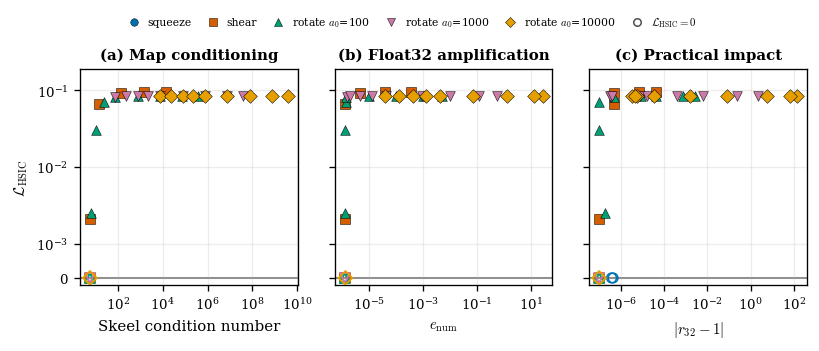

In [20]:
# ======================================================================
# EXPERIMENT 4 — numbers + figure
# ======================================================================
with pd.option_context('display.float_format', lambda v: f'{v:.6e}'):
    print(FRAME['df'][['arm_label', 'param_label', 'kappa_med', 'skeel_med',
                       'hsic', 'e_num_mean', 'r32']].to_string(index=False))

print(); stats = detector_summary(FRAME)
print(); tab   = report_table(FRAME)

with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='.*timestamp seems very low.*')
    fig4, _ = plot_frame_sweep_grid(FRAME)
plt.show()
